# 1. Data: sources, cohorts and endpoint

Question: which patients, which genes and which outcome do the later notebooks model?

What enters: four public sources with their checksums: TCGA-BRCA gene expression, the TCGA outcomes table, the TCGA-BRCA clinical supplement (receptor tests), and METABRIC.

What leaves: two patient tables in `data/` (every TCGA-BRCA cohort patient, and METABRIC) with the outcome, five clinical covariates and one column per candidate gene, plus the aggregate tables in `results/01_data/`.

Result: rendered below from the saved cohort file.

How to run: the nbconvert command in the README; the first run downloads about 5 GB.

In [1]:
import hashlib
import json
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import date
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from sksurv.nonparametric import kaplan_meier_estimator

cohort_file = Path("../results/01_data/cohort.json")
if cohort_file.exists():
    saved = json.loads(cohort_file.read_text())
    display(Markdown(f"Result: {saved['tcga']['patients']} TCGA-BRCA patients with "
                     f"{saved['tcga']['deaths']} deaths and {saved['metabric']['patients']} "
                     f"METABRIC patients with {saved['metabric']['deaths']} deaths, "
                     f"{saved['tcga']['genes']} candidate genes in both tables."))
else:
    display(Markdown("Result: not yet run."))

Result: 1064 TCGA-BRCA patients with 150 deaths and 1979 METABRIC patients with 1143 deaths, 19211 candidate genes in both tables.

## Settings

Every choice of this notebook is set here once, with its reason beside it.

In [2]:
GDC_API = "https://api.gdc.cancer.gov"  # NCI Genomic Data Commons
GDC_PAGE_SIZE = 10000                   # larger than any file list we ask for: one page holds all
TCGA_PROJECT = "TCGA-BRCA"
CDR_FILE_ID = "1b5f413e-a8d1-4d10-92eb-7c4ae739ed81"  # the TCGA-CDR workbook, PanCanAtlas page
SUPPLEMENT_NAME = "nationwidechildrens.org_clinical_patient_brca.txt"  # patient table, supplement
DATAHUB = "cBioPortal/datahub/dca75cb3f32b82d54a6f78bf0a6323e5b975aca1/public/brca_metabric"
# The datahub commit above was pinned on 2026-09-30.
HTTP_TIMEOUT = (10, 600)                # seconds to wait for a connection, then for data
DOWNLOAD_THREADS = 8                    # parallel downloads; the expression source has 1,000 files
CHUNK_BYTES = 1 << 20                   # files are read and written in pieces of 1 MiB
PRIMARY_TUMOUR_CODE = "01"              # TCGA sample-type code of a primary solid tumour
DAYS_PER_YEAR = 365.25                  # average length of a year, leap years included
DAYS_PER_MONTH = DAYS_PER_YEAR / 12     # METABRIC reports follow-up in months
CLASS_CUTS_DAYS = [365, 1095, 1825]     # 1, 3 and 5 years: class borders of the earlier pipeline
REPO = Path(subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True,
                           text=True, check=True).stdout.strip())
DATA = REPO / "data"                    # downloads and patient-level tables; ignored by git
RESULTS = REPO / "results" / "01_data"  # aggregate tables only; tracked by git
RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)
HTTP = requests.Session()               # one session, so that connections to a server are reused

## Downloading with a record

For each source we first write a manifest, the list of its files with the checksum the source publishes, the version and the date; a checksum is a short fingerprint of a file's content. Files are downloaded only when missing and compared with their checksum in every run.

In [3]:
def file_hash(path, algorithm):
    """The checksum of a file, read in pieces."""
    digest = hashlib.new(algorithm)
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(CHUNK_BYTES), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, path):
    """Fetch url into path unless the file is already there; True when a download happened."""
    if path.exists():
        return False
    partial = path.with_name(path.name + ".part")  # a half-written file must never look complete
    with HTTP.get(url, stream=True, timeout=HTTP_TIMEOUT) as response:
        response.raise_for_status()
        with open(partial, "wb") as handle:
            for chunk in response.iter_content(CHUNK_BYTES):
                handle.write(chunk)
    partial.rename(path)
    return True


def write_manifest(folder, source_version, files):
    """Record the file list of a source with its version and the date of retrieval."""
    folder.mkdir(parents=True, exist_ok=True)
    manifest = {"version": source_version, "retrieved_on": date.today().isoformat(), "files": files}
    (folder / "manifest.json").write_text(json.dumps(manifest, indent=1))

In [4]:
def matches_checksum(folder, entry):
    """Whether a downloaded file has the checksum its source published."""
    return file_hash(folder / entry["name"], entry["checksum_type"]) == entry["checksum"]


def fetch_and_verify(folder, files):
    """Download the missing files, then count the files that match their recorded checksum."""
    with ThreadPoolExecutor(DOWNLOAD_THREADS) as pool:
        fetched = pool.map(lambda entry: download(entry["url"], folder / entry["name"]), files)
        downloaded = sum(fetched)
        verified = sum(pool.map(lambda entry: matches_checksum(folder, entry), files))
    return {"downloaded in this run": downloaded, "checksum correct": verified, "files": len(files)}

## Source 1: TCGA-BRCA gene expression

We ask the NCI Genomic Data Commons (GDC) for every open-access STAR gene-count file of the project; each file holds, for one tissue sample, the read count and the TPM value (transcripts per million, a count scaled for gene length and sequencing depth) of every gene. The answer is saved as the manifest with the GDC data release, and the table counts the listed files by sample type.

In [5]:
def gdc_list_files(filters, fields):
    """Ask the GDC files index for the files that match every filter."""
    conditions = []
    for field, value in filters.items():
        condition = {"op": "=", "content": {"field": field, "value": value}}
        conditions.append(condition)
    body = {"filters": {"op": "and", "content": conditions}, "fields": ",".join(fields),
            "size": GDC_PAGE_SIZE}
    answer = HTTP.post(f"{GDC_API}/files", json=body, timeout=HTTP_TIMEOUT).json()["data"]
    complete = answer["pagination"]["total"] == len(answer["hits"])
    assert complete, "the file list must arrive complete, not as a first page"
    return answer["hits"]


def gdc_release():
    """The data release the GDC currently serves."""
    return HTTP.get(f"{GDC_API}/status", timeout=HTTP_TIMEOUT).json()["data_release"]


star_dir = DATA / "raw" / "gdc_star_counts"
if not (star_dir / "manifest.json").exists():
    filters = {"cases.project.project_id": TCGA_PROJECT,
               "data_type": "Gene Expression Quantification",
               "analysis.workflow_type": "STAR - Counts", "access": "open"}
    fields = ["file_id", "file_name", "md5sum", "cases.submitter_id", "cases.samples.sample_type",
              "associated_entities.entity_submitter_id"]
    files = []
    for hit in gdc_list_files(filters, fields):
        entry = {"name": hit["file_name"], "url": f"{GDC_API}/data/{hit['file_id']}",
                 "checksum_type": "md5", "checksum": hit["md5sum"],
                 "patient": hit["cases"][0]["submitter_id"],
                 "sample_type": hit["cases"][0]["samples"][0]["sample_type"],
                 "aliquot": hit["associated_entities"][0]["entity_submitter_id"]}
        files.append(entry)
    write_manifest(star_dir, gdc_release(), sorted(files, key=lambda entry: entry["aliquot"]))
star_listing = pd.DataFrame(json.loads((star_dir / "manifest.json").read_text())["files"])
star_listing["sample_type"].value_counts().rename("files").to_frame()

,files
sample_type,
Primary Tumor,1111
Solid Tissue Normal,113
Metastatic,7


## One primary tumour sample per patient

We keep primary tumour samples only and exactly one per patient, because normal tissue and metastases differ from the primary tumour and a patient with two samples would count twice. The GDC records a preservation method for some samples (FFPE tissue is stored in wax and yields degraded RNA; Unknown means not recorded), fetched once and saved beside the manifest. The table counts the files of patients with several files by vial letter and recorded method.

In [6]:
primary = star_listing[star_listing["sample_type"] == "Primary Tumor"].copy()
primary["file_id"] = primary["url"].str.rsplit("/", n=1).str[1]
preservation_path = star_dir / "preservation.json"
if not preservation_path.exists():
    chosen = {"op": "in", "content": {"field": "file_id", "value": sorted(primary["file_id"])}}
    body = {"filters": chosen, "fields": "file_id,cases.samples.preservation_method",
            "size": GDC_PAGE_SIZE}
    answer = HTTP.post(f"{GDC_API}/files", json=body, timeout=HTTP_TIMEOUT).json()["data"]
    assert len(answer["hits"]) == len(primary), "the preservation list must arrive complete"
    methods = {}
    for hit in answer["hits"]:
        methods[hit["file_id"]] = hit["cases"][0]["samples"][0]["preservation_method"]
    record = {"retrieved_on": date.today().isoformat(), "release": gdc_release(),
              "preservation_method": methods}
    preservation_path.write_text(json.dumps(record, indent=1))
preservation = json.loads(preservation_path.read_text())["preservation_method"]
primary["preservation"] = primary["file_id"].map(preservation)
primary["vial"] = primary["aliquot"].str[15]      # the letter after the sample-type code
primary["plate"] = primary["aliquot"].str[20:24]  # a barcode field, used only as a sort key
several = primary[primary.duplicated("patient", keep=False)]
duplicate_table = pd.crosstab(several["vial"], several["preservation"])
duplicate_table.index.name = "vial letter"
duplicate_table.columns.name = "preservation method"
duplicate_table.to_csv(RESULTS / "duplicate_samples.csv")
duplicate_table

preservation method,FFPE,Unknown
vial letter,,
A,0,16
B,10,0
C,1,0


When a patient has several files, those recorded as FFPE are set aside and the lowest plate number among the rest is kept; the plate number is a barcode field used only as a deterministic sort key, not a quality claim. The check confirms that this rule selects the same files as the barcode-first rule used before, and the table counts the recorded preservation method of every selected file.

In [7]:
def choose_file(files):
    """Set the files recorded as FFPE aside, then keep the lowest plate number as a tie-break."""
    if len(files) == 1:
        return files
    kept = files[files["preservation"] != "FFPE"]
    assert kept["plate"].is_unique, "two remaining aliquots share a plate number: no tie-break"
    return kept.sort_values("plate").head(1)


chosen_files = []
for patient, files in primary.groupby("patient"):
    chosen_files.append(choose_file(files))
tcga_samples = pd.concat(chosen_files).set_index("patient").sort_index()
first_barcode = primary.sort_values("aliquot").groupby("patient").head(1)
assert set(tcga_samples["name"]) == set(first_barcode["name"]), "the rule selects other files"
sample_codes = tcga_samples["aliquot"].str[13:15]  # the sample type inside the barcode
assert (sample_codes == PRIMARY_TUMOUR_CODE).all(), "a selected sample is not a primary tumour"
assert tcga_samples.index.is_unique, "a patient has more than one selected sample"
ffpe_selected = int((tcga_samples["preservation"] == "FFPE").sum())
display(Markdown(f"{len(primary)} primary tumour files belong to {len(tcga_samples)} patients; "
                 f"{int(several['patient'].nunique())} patients have more than one file. "
                 f"{ffpe_selected} selected files are FFPE, each the only file of its patient; "
                 "they stay in the cohort by the supervisors' decision of 22 October 2026."))
preservation_selected = tcga_samples["preservation"].fillna("not recorded").value_counts()
preservation_selected = preservation_selected.rename_axis("recorded preservation method")
preservation_selected = preservation_selected.to_frame("selected files")
preservation_selected.to_csv(RESULTS / "preservation_selected.csv")
preservation_selected

1111 primary tumour files belong to 1095 patients; 11 patients have more than one file. 2 selected files are FFPE, each the only file of its patient; they stay in the cohort by the supervisors' decision of 22 October 2026.

,selected files
recorded preservation method,
OCT,679
Unknown,414
FFPE,2


## The four sources

One table describes every source: what it is, where it comes from, its terms of use, the paper to cite and where its checksum comes from. The outcomes come from the TCGA Pan-Cancer Clinical Data Resource (CDR, Liu et al. 2018), the receptor tests from the TCGA-BRCA clinical supplement at the GDC, and METABRIC from the cBioPortal datahub pinned to one commit.

In [8]:
cdr_dir = DATA / "raw" / "tcga_cdr"
supplement_dir = DATA / "raw" / "gdc_clinical_supplement"
metabric_dir = DATA / "raw" / "metabric"
cdr_url = f"{GDC_API}/data/{CDR_FILE_ID}"
datahub_address = DATAHUB.replace(DATAHUB.split("/")[2], " [commit] ")
SOURCES = {
    "TCGA-BRCA gene expression": {
        "folder": star_dir,
        "what it is": "STAR gene counts and TPM per Ensembl gene (GENCODE v36), one file per "
                      "tissue sample",
        "where from": f"{GDC_API}/files with project {TCGA_PROJECT}, Gene Expression "
                      f"Quantification, STAR - Counts, open access; each file from "
                      f"{GDC_API}/data/[file id]",
        "terms of use": "Open access, no login. GDC open data fall under the NIH Genomic Data "
                        "Sharing policy: do not attempt to identify participants, and acknowledge "
                        "the data set and the repository. TCGA asks for an acknowledgement of the "
                        "TCGA Research Network (https://www.cancer.gov/tcga).",
        "citation": "Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC); "
                    "The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412 "
                    "(TCGA-BRCA)",
        "source checksum": "MD5 listed in the GDC files index"},
    "TCGA outcomes (CDR)": {
        "folder": cdr_dir,
        "what it is": "Curated clinical table of all TCGA cancer types with four outcome endpoints "
                      "(OS, DSS, DFI, PFI)",
        "where from": cdr_url + ", linked from "
                      "https://gdc.cancer.gov/about-data/publications/pancanatlas",
        "terms of use": "Open access at the GDC under the same policy as the expression files. "
                        "The article is open access under CC BY-NC-ND 4.0.",
        "citation": "Liu et al., Cell 2018, doi:10.1016/j.cell.2018.02.052",
        "source checksum": "MD5 sent by the GDC in the Content-MD5 response header"}}

In [9]:
SOURCES |= {
    "TCGA-BRCA clinical supplement": {
        "folder": supplement_dir,
        "what it is": "Patient table of the clinical supplement (BCR Biotab), used for ER, PR and "
                      "HER2 status",
        "where from": f"{GDC_API}/files with project {TCGA_PROJECT} and file name "
                      f"{SUPPLEMENT_NAME}; the file from {GDC_API}/data/[file id]",
        "terms of use": "Open access at the GDC under the same policy as the expression files.",
        "citation": "The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412; "
                    "Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC)",
        "source checksum": "MD5 listed in the GDC files index"},
    "METABRIC": {
        "folder": metabric_dir,
        "what it is": "Clinical patient table, clinical sample table and Illumina HT-12 v3 "
                      "expression matrix (log2 intensity) of the study brca_metabric",
        "where from": "https://media.githubusercontent.com/media/ " + datahub_address
                      + "/ [file name]",
        "terms of use": "Open Database License (ODbL) 1.0, stated in the LICENSE file of the study "
                        "folder: free to share and adapt with attribution; derived data sets stay "
                        "open under the same licence.",
        "citation": "Curtis et al., Nature 2012, doi:10.1038/nature10983; Pereira et al., Nat "
                    "Commun 2016, doi:10.1038/ncomms11479 (METABRIC); Cerami et al., Cancer Discov "
                    "2012, doi:10.1158/2159-8290.CD-12-0095 (cBioPortal)",
        "source checksum": "SHA-256 recorded in the Git LFS pointer file"}}

Each of the three remaining sources gets its manifest once: the CDR sends its MD5 in a response header, the supplement is looked up in the GDC index by name, and METABRIC's files carry their SHA-256 in the Git LFS pointer files of the datahub. The output counts, per source, the files downloaded in this run and the files whose checksum is correct; the check stops the notebook on any mismatch.

In [10]:
def cdr_files():
    """The CDR workbook with the checksum the GDC sends in its response header."""
    with HTTP.get(cdr_url, stream=True, timeout=HTTP_TIMEOUT) as response:  # headers only here
        cdr_md5 = response.headers["Content-MD5"]
    return [{"name": "TCGA-CDR-SupplementalTableS1.xlsx", "url": cdr_url,
             "checksum_type": "md5", "checksum": cdr_md5}]


def supplement_files():
    """The clinical supplement's patient table, looked up by name in the GDC index."""
    filters = {"cases.project.project_id": TCGA_PROJECT, "file_name": SUPPLEMENT_NAME,
               "access": "open"}
    hit, = gdc_list_files(filters, ["file_id", "file_name", "md5sum"])  # fails unless one file
    return [{"name": hit["file_name"], "url": f"{GDC_API}/data/{hit['file_id']}",
             "checksum_type": "md5", "checksum": hit["md5sum"]}]


def metabric_files():
    """The three METABRIC files with the SHA-256 of their Git LFS pointers."""
    files = []
    for name in ["data_clinical_patient.txt", "data_clinical_sample.txt",
                 "data_mrna_illumina_microarray.txt"]:
        pointer = HTTP.get(f"https://raw.githubusercontent.com/{DATAHUB}/{name}",
                           timeout=HTTP_TIMEOUT).text
        entry = {"name": name, "checksum_type": "sha256",
                 "url": f"https://media.githubusercontent.com/media/{DATAHUB}/{name}",
                 "checksum": pointer.split("oid sha256:")[1].split()[0]}
        files.append(entry)
    return files

In [11]:
manifests_to_write = {
    "TCGA outcomes (CDR)": ("Supplemental Table S1 of Liu et al. 2018, GDC file " + CDR_FILE_ID,
                            cdr_files),
    "TCGA-BRCA clinical supplement": (gdc_release, supplement_files),
    "METABRIC": ("cBioPortal datahub commit " + DATAHUB.split("/")[2], metabric_files)}
for name, (source_version, list_files) in manifests_to_write.items():
    if not (SOURCES[name]["folder"] / "manifest.json").exists():
        if callable(source_version):
            source_version = source_version()
        write_manifest(SOURCES[name]["folder"], source_version, list_files())
checks = {}
for name, source in SOURCES.items():
    manifest = json.loads((source["folder"] / "manifest.json").read_text())
    files = manifest["files"]
    if name == "TCGA-BRCA gene expression":
        files = tcga_samples.to_dict("records")  # only the selected files are fetched
    checks[name] = fetch_and_verify(source["folder"], files)
    assert checks[name]["checksum correct"] == checks[name]["files"], "a file fails its checksum"
    source.update(version=manifest["version"], retrieved_on=manifest["retrieved_on"])
pd.DataFrame(checks).T

,downloaded in this run,checksum correct,files
TCGA-BRCA gene expression,0,1095,1095
TCGA outcomes (CDR),0,1,1
TCGA-BRCA clinical supplement,0,1,1
METABRIC,0,3,3


In [12]:
source_rows = {}
for name, source in SOURCES.items():
    source_rows[name] = {"what it is": source["what it is"], "where from": source["where from"],
                         "version": source["version"], "retrieved on": source["retrieved_on"],
                         "terms of use": source["terms of use"], "citation": source["citation"],
                         "source checksum": source["source checksum"],
                         "files checked": checks[name]["checksum correct"],
                         "manifest sha256": file_hash(source["folder"] / "manifest.json", "sha256")}
sources_table = pd.DataFrame(source_rows).T
sources_table.index.name = "source"
sources_table.to_csv(RESULTS / "sources.csv")
sources_table.T

source,TCGA-BRCA gene expression,TCGA outcomes (CDR),TCGA-BRCA clinical supplement,METABRIC
what it is,"STAR gene counts and TPM per Ensembl gene (GENCODE v36), one file per tissue sample","Curated clinical table of all TCGA cancer types with four outcome endpoints (OS, DSS, DFI, PFI)","Patient table of the clinical supplement (BCR Biotab), used for ER, PR and HER2 status","Clinical patient table, clinical sample table and Illumina HT-12 v3 expression matrix (log2 intensity) of the study brca_metabric"
where from,"https://api.gdc.cancer.gov/files with project TCGA-BRCA, Gene Expression Quantification, STAR - Counts, open access; each file from https://api.gdc.cancer.gov/data/[file id]","https://api.gdc.cancer.gov/data/1b5f413e-a8d1-4d10-92eb-7c4ae739ed81, linked from https://gdc.cancer.gov/about-data/publications/pancanatlas",https://api.gdc.cancer.gov/files with project TCGA-BRCA and file name nationwidechildrens.org_clinical_patient_brca.txt; the file from https://api.gdc.cancer.gov/data/[file id],https://media.githubusercontent.com/media/ cBioPortal/datahub/ [commit] /public/brca_metabric/ [file name]
version,"Data Release 46.0 - August 10, 2026","Supplemental Table S1 of Liu et al. 2018, GDC file 1b5f413e-a8d1-4d10-92eb-7c4ae739ed81","Data Release 46.0 - August 10, 2026",cBioPortal datahub commit dca75cb3f32b82d54a6f78bf0a6323e5b975aca1
retrieved on,2026-09-30,2026-09-30,2026-09-30,2026-09-30
terms of use,"Open access, no login. GDC open data fall under the NIH Genomic Data Sharing policy: do not attempt to identify participants, and acknowledge the data set and the repository. TCGA asks for an acknowledgement of the TCGA Research Network (https://www.cancer.gov/tcga).",Open access at the GDC under the same policy as the expression files. The article is open access under CC BY-NC-ND 4.0.,Open access at the GDC under the same policy as the expression files.,"Open Database License (ODbL) 1.0, stated in the LICENSE file of the study folder: free to share and adapt with attribution; derived data sets stay open under the same licence."
citation,"Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC); The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412 (TCGA-BRCA)","Liu et al., Cell 2018, doi:10.1016/j.cell.2018.02.052","The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412; Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC)","Curtis et al., Nature 2012, doi:10.1038/nature10983; Pereira et al., Nat Commun 2016, doi:10.1038/ncomms11479 (METABRIC); Cerami et al., Cancer Discov 2012, doi:10.1158/2159-8290.CD-12-0095 (cBioPortal)"
source checksum,MD5 listed in the GDC files index,MD5 sent by the GDC in the Content-MD5 response header,MD5 listed in the GDC files index,SHA-256 recorded in the Git LFS pointer file
files checked,1095,1,1,3
manifest sha256,a4dc598e3a6b33a25b41f5b5a0333468c40608ccafcebcb8af691953b372ea57,7aa992b9354a6cfb216484cc1cec50cf4ea21182e9a7ee4d877723464f6dcfeb,5a46021ee4c699a7b97111b409baff876143ef8ff5ebd68156198b3faffff7fa,8b70a304d2b057c343ee233f23e45972654eed7cb5343625c49f197a0be7bf15


## TCGA-BRCA cohort

The cohort starts from the TCGA-BRCA patients in the CDR and applies five rules in order: no redaction flag (TCGA marked those cases as problematic), women only (the external cohort is all female), a primary tumour RNA-seq file, a recorded overall survival status and time, and a time above zero. No missing outcome is filled in; the table shows the patients and deaths left after each rule.

In [13]:
def apply_rules(table, start_label, rules):
    """Apply the rules in order. Return the rows that remain and the counts after each rule."""
    start = {"rule": start_label, "patients": len(table), "deaths": int(table["os_event"].sum())}
    counts = [start]
    for label, keep in rules:
        table = table[keep(table)]
        count = {"rule": label, "patients": len(table), "deaths": int(table["os_event"].sum())}
        counts.append(count)
    return table.sort_index(), pd.DataFrame(counts).set_index("rule")


cdr = pd.read_excel(cdr_dir / "TCGA-CDR-SupplementalTableS1.xlsx", sheet_name="TCGA-CDR",
                    index_col="bcr_patient_barcode")
cdr_names = {"OS": "os_event", "OS.time": "os_days"}
cdr = cdr[cdr["type"] == "BRCA"].rename(columns=cdr_names)
tcga_rules = [
    ("without the redaction flag", lambda t: t["Redaction"].isna()),
    ("women", lambda t: t["gender"] == "FEMALE"),
    ("with a primary tumour RNA-seq file", lambda t: t.index.isin(tcga_samples.index)),
    ("with OS status and OS time recorded", lambda t: t["os_event"].notna() & t["os_days"].notna()),
    ("with OS time above 0", lambda t: t["os_days"] > 0)]
tcga, tcga_counts = apply_rules(cdr, "TCGA-BRCA patients in the CDR", tcga_rules)
tcga_counts.to_csv(RESULTS / "cohort_tcga.csv")
assert tcga["Redaction"].isna().all() and (tcga["gender"] == "FEMALE").all(), "an exclusion failed"
display(tcga_counts)
display(Markdown("RNA-seq patients without a CDR record, and so without an outcome: "
                 f"{int((~tcga_samples.index.isin(cdr.index)).sum())}."))

,patients,deaths
rule,,
TCGA-BRCA patients in the CDR,1097,151
without the redaction flag,1092,151
women,1080,150
with a primary tumour RNA-seq file,1078,150
with OS status and OS time recorded,1077,150
with OS time above 0,1064,150


RNA-seq patients without a CDR record, and so without an outcome: 1.

## METABRIC cohort

The corresponding rules apply to METABRIC: a column in the expression matrix, a recorded overall survival status and time, and a time above zero; follow-up is given in months and converted to days. The checks confirm that each patient has one sample of the same name and that the cohort is all female, which is why men were dropped from TCGA.

In [14]:
metabric_patients = pd.read_csv(metabric_dir / "data_clinical_patient.txt", sep="\t", comment="#",
                                index_col="PATIENT_ID")
metabric_samples = pd.read_csv(metabric_dir / "data_clinical_sample.txt", sep="\t", comment="#",
                               index_col="PATIENT_ID")
metabric_expression = pd.read_csv(metabric_dir / "data_mrna_illumina_microarray.txt", sep="\t")
status_codes = {"0:LIVING": 0, "1:DECEASED": 1}
metabric_patients["os_event"] = metabric_patients["OS_STATUS"].map(status_codes)
metabric_patients["os_days"] = metabric_patients["OS_MONTHS"] * DAYS_PER_MONTH
metabric_rules = [
    ("with a column in the expression matrix", lambda t: t.index.isin(metabric_expression.columns)),
    ("with OS status and OS time recorded", lambda t: t["os_event"].notna() & t["os_days"].notna()),
    ("with OS time above 0", lambda t: t["os_days"] > 0)]
metabric_start = "METABRIC patients in the clinical table"
metabric, metabric_counts = apply_rules(metabric_patients, metabric_start, metabric_rules)
metabric_counts.to_csv(RESULTS / "cohort_metabric.csv")
same_name = metabric_samples["SAMPLE_ID"] == metabric_samples.index
assert same_name.all(), "a METABRIC sample is not named like its patient"
assert metabric_samples.index.is_unique, "a METABRIC sample appears twice"
assert metabric_patients.index.is_unique, "a METABRIC patient appears twice"
assert (metabric_patients["SEX"] == "Female").all(), "the METABRIC cohort is not all female"
metabric_counts

,patients,deaths
rule,,
METABRIC patients in the clinical table,2509,1144
with a column in the expression matrix,1980,1143
with OS status and OS time recorded,1980,1143
with OS time above 0,1979,1143


## Clinical covariates

Five clinical variables are kept for both cohorts: age at diagnosis, tumour stage reduced to its main level, and the status of the receptors ER, PR and HER2, where a test not done or unclear becomes the level unknown. For HER2 in TCGA the second test (FISH) decides where the first (IHC) gives no clear answer. Nobody is dropped for a missing covariate.

In [15]:
def receptor_status(status):
    """Keep positive and negative; every other value, missing ones included, becomes 'unknown'."""
    spelling = {"positve": "positive"}  # the METABRIC table spells it this way
    status = status.str.lower().replace(spelling)
    return status.where(status.isin(["positive", "negative"]), "unknown")


# Lines 2 and 3 of the file repeat the header in two other vocabularies and are skipped.
supplement = pd.read_csv(supplement_dir / SUPPLEMENT_NAME, sep="\t", skiprows=[1, 2],
                         index_col="bcr_patient_barcode").reindex(tcga.index)
her2_by_ihc = receptor_status(supplement["her2_status_by_ihc"])
her2_by_fish = receptor_status(supplement["her2_fish_status"])
stage_pattern = r"^Stage (IV|III|II|I)"
tcga_stage = tcga["ajcc_pathologic_tumor_stage"].str.extract(stage_pattern, expand=False)
tcga_columns = {
    "os_days": tcga["os_days"], "os_event": tcga["os_event"].astype(int),
    "age": tcga["age_at_initial_pathologic_diagnosis"], "stage": tcga_stage.fillna("unknown"),
    "er": receptor_status(supplement["er_status_by_ihc"]),
    "pr": receptor_status(supplement["pr_status_by_ihc"]),
    "her2": her2_by_ihc.where(her2_by_ihc != "unknown", her2_by_fish)}  # FISH decides unclear cases
tcga_clinical = pd.DataFrame(tcga_columns)
metabric_sample = metabric_samples.loc[metabric.index]
stage_names = {0: "0", 1: "I", 2: "II", 3: "III", 4: "IV"}
metabric_columns = {
    "os_days": metabric["os_days"], "os_event": metabric["os_event"].astype(int),
    "age": metabric["AGE_AT_DIAGNOSIS"],
    "stage": metabric_sample["TUMOR_STAGE"].map(stage_names).fillna("unknown"),
    "er": receptor_status(metabric["ER_IHC"]), "pr": receptor_status(metabric_sample["PR_STATUS"]),
    "her2": receptor_status(metabric_sample["HER2_STATUS"])}
metabric_clinical = pd.DataFrame(metabric_columns)

IHC stains the HER2 protein and is read as a score where 2+ is equivocal; FISH counts the copies of the HER2 gene. The ASCO/CAP guideline (Wolff et al., J Clin Oncol 2013, doi:10.1200/JCO.2013.50.9984; update 2018, doi:10.1200/JCO.2018.77.8738) calls for the other test when a result is equivocal, and our rule follows that order on the recorded categories only, as a study rule. The first table crosses the two results, the second shows what the rule changes.

In [16]:
def test_levels(status):
    """The recorded level of a HER2 test; a test not done or not recorded is one level."""
    levels = ["Positive", "Negative", "Equivocal", "Indeterminate"]
    return status.where(status.isin(levels), "not done or missing").str.lower()


level_order = ["positive", "negative", "equivocal", "indeterminate", "not done or missing"]
ihc_by_fish = pd.crosstab(test_levels(supplement["her2_status_by_ihc"]),
                          test_levels(supplement["her2_fish_status"]))
ihc_by_fish = ihc_by_fish.reindex(index=level_order, columns=level_order).fillna(0).astype(int)
ihc_by_fish.index.name = "IHC result"
ihc_by_fish.columns.name = "FISH result"
ihc_by_fish.to_csv(RESULTS / "her2_ihc_by_fish.csv")
her2_columns = {"IHC only": her2_by_ihc.value_counts(),
                "IHC, then FISH": tcga_clinical["her2"].value_counts()}
her2_rule_table = pd.DataFrame(her2_columns)
her2_rule_table.index.name = "HER2 level"
her2_rule_table.to_csv(RESULTS / "her2_rule.csv")
display(ihc_by_fish, her2_rule_table)
clear = ["positive", "negative"]
display(Markdown(f"{int(ihc_by_fish.loc[clear, clear].to_numpy().sum())} patients have a clear "
                 f"result on both tests: {int(ihc_by_fish.loc['positive', 'negative'])} are "
                 f"positive by IHC and negative by FISH, "
                 f"{int(ihc_by_fish.loc['negative', 'positive'])} the reverse; for all of them the "
                 "rule follows IHC."))

FISH result,positive,negative,equivocal,indeterminate,not done or missing
IHC result,,,,,
positive,40,12,2,1,101
negative,3,115,0,3,428
equivocal,17,137,3,0,18
indeterminate,2,6,0,0,4
not done or missing,8,53,0,0,111


,IHC only,"IHC, then FISH"
HER2 level,,
negative,549,745
positive,156,183
unknown,359,136


170 patients have a clear result on both tests: 12 are positive by IHC and negative by FISH, 3 the reverse; for all of them the rule follows IHC.

The table counts the patients at each level of the four categorical covariates in both cohorts; a level that only one cohort uses will need a decision before the external evaluation.

In [17]:
covariate_names = ["stage", "er", "pr", "her2"]
tcga_levels, metabric_levels = {}, {}
for name in covariate_names:
    tcga_levels[name] = tcga_clinical[name].value_counts()
    metabric_levels[name] = metabric_clinical[name].value_counts()
level_columns = {"TCGA-BRCA": pd.concat(tcga_levels), "METABRIC": pd.concat(metabric_levels)}
covariate_table = pd.DataFrame(level_columns).fillna(0).astype(int)
covariate_table.index.names = ["covariate", "level"]
covariate_table.to_csv(RESULTS / "covariates.csv")
display(covariate_table)
display(Markdown(f"Median age at diagnosis: {tcga_clinical['age'].median():.0f} years in TCGA-BRCA "
                 f"and {metabric_clinical['age'].median():.0f} in METABRIC; age is missing for "
                 f"{int(tcga_clinical['age'].isna().sum())} and "
                 f"{int(metabric_clinical['age'].isna().sum())} patients."))

TCGA-BRCA  METABRIC
covariate level                        
er        negative        236       439
          positive        780      1498
          unknown          48        42
her2      negative        745      1732
          positive        183       247
          unknown         136         0
pr        negative        336       939
          positive        677      1040
          unknown          51         0
stage     0                 0        12
          I               179       501
          II              600       825
          III             242       118
          IV               19        10
          unknown          24       513

Median age at diagnosis: 58 years in TCGA-BRCA and 62 in METABRIC; age is missing for 0 and 0 patients.

## Unknown values and follow-up

An unknown value can predict death for the wrong reason, if it marks patients from an earlier period who were followed longer. Follow-up is estimated by the reverse Kaplan-Meier method (the library's estimator with the death indicator reversed, which treats a death as the end of observation); the table gives patients, deaths and median follow-up per level of each covariate in TCGA.

In [18]:
def first_time_at_half(years, curve):
    """The first time at which a step curve falls to one half or below; missing if it never does."""
    if (curve <= 0.5).any():
        return years[curve <= 0.5][0]
    return np.nan


def median_follow_up(clinical):
    """Median follow-up in years by reverse Kaplan-Meier: the library's censoring distribution."""
    died = clinical["os_event"].astype(bool)
    years, still_observed = kaplan_meier_estimator(died, clinical["os_days"] / DAYS_PER_YEAR,
                                                   reverse=True)
    return first_time_at_half(years, still_observed)


def median_survival(clinical):
    """Median survival in years by Kaplan-Meier; missing when the curve never reaches one half."""
    died = clinical["os_event"].astype(bool)
    years, alive = kaplan_meier_estimator(died, clinical["os_days"] / DAYS_PER_YEAR)
    return first_time_at_half(years, alive)


follow_up_rows = {}
for name in covariate_names:
    for level, group in tcga_clinical.groupby(name):
        follow_up_rows[(name, level)] = {
            "patients": len(group), "deaths": int(group["os_event"].sum()),
            "deaths (%)": round(100 * group["os_event"].mean(), 1),
            "median follow-up (years)": round(median_follow_up(group), 1)}
follow_up_table = pd.DataFrame.from_dict(follow_up_rows, orient="index")
follow_up_table.index.names = ["covariate", "level"]
follow_up_table.to_csv(RESULTS / "unknown_values_and_follow_up.csv")
display(follow_up_table)
unknown = follow_up_table.xs("unknown", level="level")["median follow-up (years)"]
display(Markdown(f"Median follow-up is {median_follow_up(tcga_clinical):.1f} years in the whole "
                 f"cohort; among patients with an unknown value it is {unknown['stage']} years for "
                 f"stage, {unknown['er']} for ER, {unknown['pr']} for PR and {unknown['her2']} for "
                 "HER2. A blank means that the censoring curve never fell to one half."))

patients  deaths  deaths (%)  median follow-up (years)
covariate level                                                           
stage     I              179      16         8.9                       3.6
          II             600      65        10.8                       2.4
          III            242      44        18.2                       2.3
          IV              19      14        73.7                       NaN
          unknown         24      11        45.8                      11.1
er        negative       236      41        17.4                       2.8
          positive       780      99        12.7                       2.6
          unknown         48      10        20.8                       2.5
pr        negative       336      56        16.7                       2.8
          positive       677      85        12.6                       2.5
          unknown         51       9        17.6                       2.5
her2      negative       745      80        10.7                       2.5
          positive       183      24        13.1                       2.5
          unknown        136      46        33.8                       4.0

Median follow-up is 2.7 years in the whole cohort; among patients with an unknown value it is 11.1 years for stage, 2.5 for ER, 2.5 for PR and 4.0 for HER2. A blank means that the censoring curve never fell to one half.

## The endpoint: overall survival as time and event

The outcome is overall survival, the time from diagnosis to death from any cause; a patient alive at the last contact is censored, which means only that survival is longer than the follow-up. The table gives three medians per cohort (observed time, follow-up by reverse Kaplan-Meier, survival by Kaplan-Meier), and the figure shows the Kaplan-Meier curves with their 95% bands.

,patients,deaths,censored (%),median observed time (years),median follow-up (years),median survival (years),longest observed time (years)
TCGA-BRCA,1064,150,85.9,2.4,2.7,10.8,23.6
METABRIC,1979,1143,42.2,9.7,16.3,13.0,29.6


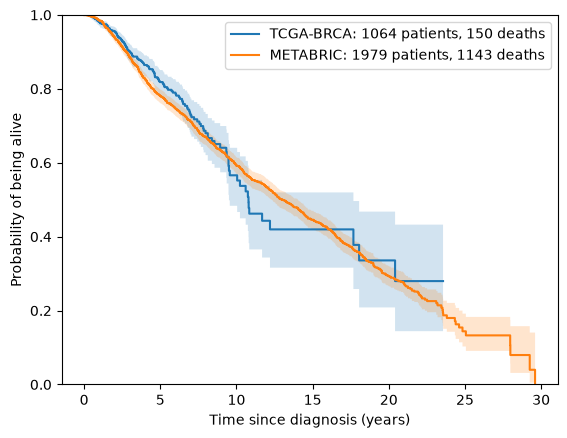

In [19]:
outcome_rows = []
for clinical in [tcga_clinical, metabric_clinical]:
    row = {"patients": len(clinical), "deaths": int(clinical["os_event"].sum()),
           "censored (%)": round(100 * (1 - clinical["os_event"].mean()), 1),
           "median observed time (years)": round(clinical["os_days"].median() / DAYS_PER_YEAR, 1),
           "median follow-up (years)": round(median_follow_up(clinical), 1),
           "median survival (years)": round(median_survival(clinical), 1),
           "longest observed time (years)": round(clinical["os_days"].max() / DAYS_PER_YEAR, 1)}
    outcome_rows.append(row)
outcome_table = pd.DataFrame(outcome_rows, index=["TCGA-BRCA", "METABRIC"])
outcome_table.to_csv(RESULTS / "outcome_summary.csv")
display(outcome_table)
figure, axis = plt.subplots()
for name, clinical in [("TCGA-BRCA", tcga_clinical), ("METABRIC", metabric_clinical)]:
    died = clinical["os_event"].astype(bool)
    years, alive, band = kaplan_meier_estimator(died, clinical["os_days"] / DAYS_PER_YEAR,
                                                conf_type="log-log")
    axis.step(years, alive, where="post",
              label=f"{name}: {len(clinical)} patients, {clinical['os_event'].sum()} deaths")
    axis.fill_between(years, band[0], band[1], step="post", alpha=0.2)
axis.set_xlabel("Time since diagnosis (years)")
axis.set_ylabel("Probability of being alive")
axis.set_ylim(0, 1)
axis.legend()
plt.show()

The CDR paper advises caution with overall and disease-specific survival in breast cancer because TCGA's follow-up is short, so the first table counts the events of every available endpoint. The second counts the deaths by cause (the CDR approximates the cause from the disease-specific endpoint; METABRIC records it), and the third the levels of the CDR's own recorded cause-of-death column, where a bracketed level is its missing-value code.

In [20]:
vital_known = metabric["VITAL_STATUS"].notna()
died_of_disease = (metabric["VITAL_STATUS"] == "Died of Disease").where(vital_known)
relapse_codes = {"0:Not Recurred": 0, "1:Recurred": 1}
endpoint_flags = {
    ("TCGA-BRCA", "OS: death from any cause"): tcga["os_event"],
    ("TCGA-BRCA", "DSS: death from the disease"): tcga["DSS"],
    ("TCGA-BRCA", "DFI: return after a disease-free period"): tcga["DFI"],
    ("TCGA-BRCA", "PFI: progression, return or death from the disease"): tcga["PFI"],
    ("METABRIC", "OS: death from any cause"): metabric["os_event"],
    ("METABRIC", "death from the disease"): died_of_disease,
    ("METABRIC", "relapse"): metabric["RFS_STATUS"].map(relapse_codes)}
endpoint_columns = {}
for key, flag in endpoint_flags.items():
    endpoint_columns[key] = {"patients with a value": int(flag.notna().sum()),
                             "events": int(flag.sum())}
endpoint_table = pd.DataFrame(endpoint_columns).T
endpoint_table.index.names = ["cohort", "endpoint"]
endpoint_table.to_csv(RESULTS / "endpoints.csv")
tcga_deaths = tcga.loc[tcga["os_event"] == 1, "DSS"]
metabric_deaths = metabric.loc[metabric["os_event"] == 1, "VITAL_STATUS"]
cause_counts = {
    ("TCGA-BRCA", "from the disease"): int((tcga_deaths == 1).sum()),
    ("TCGA-BRCA", "from another cause, as the CDR approximates it"): int((tcga_deaths == 0).sum()),
    ("TCGA-BRCA", "no value"): int(tcga_deaths.isna().sum()),
    ("METABRIC", "from the disease"): int((metabric_deaths == "Died of Disease").sum()),
    ("METABRIC", "from other causes"): int((metabric_deaths == "Died of Other Causes").sum()),
    ("METABRIC", "cause not recorded"): int(metabric_deaths.isna().sum())}
deaths_by_cause = pd.Series(cause_counts, name="deaths").to_frame()
deaths_by_cause.index.names = ["cohort", "cause of death"]
deaths_by_cause.to_csv(RESULTS / "deaths_by_cause.csv")
recorded_cause = tcga.loc[tcga["os_event"] == 1, "cause_of_death"].fillna("not recorded")
cause_levels = recorded_cause.value_counts().rename_axis("recorded cause of death")
cause_levels = cause_levels.to_frame("TCGA-BRCA deaths")
cause_levels.to_csv(RESULTS / "cause_of_death_tcga.csv")
display(endpoint_table, deaths_by_cause, cause_levels)

patients with a value  \
cohort    endpoint                                                                    
TCGA-BRCA OS: death from any cause                                             1064   
          DSS: death from the disease                                          1045   
          DFI: return after a disease-free period                               923   
          PFI: progression, return or death from the disease                   1064   
METABRIC  OS: death from any cause                                             1979   
          death from the disease                                               1978   
          relapse                                                              1978   

                                                              events  
cohort    endpoint                                                    
TCGA-BRCA OS: death from any cause                               150  
          DSS: death from the disease                             82  
          DFI: return after a disease-free period                 84  
          PFI: progression, return or death from the disease     144  
METABRIC  OS: death from any cause                              1143  
          death from the disease                                 646  
          relapse                                                803

deaths
cohort    cause of death                                        
TCGA-BRCA from the disease                                    82
          from another cause, as the CDR approximates it      49
          no value                                            19
METABRIC  from the disease                                   646
          from other causes                                  496
          cause not recorded                                   1

,TCGA-BRCA deaths
recorded cause of death,
[Not Available],150


## Survival classes of the earlier pipeline

The earlier pipeline replaced the outcome by four classes of survival time cut at 1, 3 and 5 years. A censored patient in the class up to 1 year was last seen alive within the year and may have lived much longer, yet the class counts that patient with those who died; the table shows how many patients of each class are censored, which is why the rebuild keeps time and event.

In [21]:
class_labels = ["up to 1 year", "1 to 3 years", "3 to 5 years", "over 5 years"]
class_bins = [0, *CLASS_CUTS_DAYS, np.inf]
time_class = pd.cut(tcga_clinical["os_days"], bins=class_bins, labels=class_labels)
by_class = tcga_clinical.groupby(time_class, observed=False)["os_event"]
class_table = by_class.agg(patients="size", deaths="sum")
class_table["censored"] = class_table["patients"] - class_table["deaths"]
class_table["censored (%)"] = (100 * class_table["censored"] / class_table["patients"]).round(1)
class_table.index.name = "OS time"
class_table.to_csv(RESULTS / "survival_classes.csv")
display(class_table)
shortest = class_table.iloc[0]
display(Markdown(f"In the class {class_table.index[0]}, {shortest['censored']:.0f} of "
                 f"{shortest['patients']:.0f} patients ({shortest['censored (%)']}%) are "
                 "censored."))

,patients,deaths,censored,censored (%)
OS time,,,,
up to 1 year,163,19,144,88.3
1 to 3 years,470,49,421,89.6
3 to 5 years,182,30,152,83.5
over 5 years,249,52,197,79.1


In the class up to 1 year, 144 of 163 patients (88.3%) are censored.

## Expression matrices and the candidate gene pool

The TPM column of every cohort patient's file goes into one matrix, patients by genes, as log2(TPM + 1); nothing here looks across patients, since filtering and scaling belong to the training folds of notebook 3. The check confirms that every file lists the same genes in the same order.

In [22]:
def read_star_file(name, columns):
    """The gene rows of one expression file; its first four rows are mapping statistics."""
    table = pd.read_csv(star_dir / name, sep="\t", comment="#", usecols=columns)
    return table[~table["gene_id"].str.startswith("N_")].reset_index(drop=True)


tcga_genes = read_star_file(tcga_samples["name"].iloc[0], ["gene_id", "gene_name", "gene_type"])
tpm = {}
for patient, name in tcga_samples.loc[tcga.index, "name"].items():
    table = read_star_file(name, ["gene_id", "tpm_unstranded"])
    assert table["gene_id"].equals(tcga_genes["gene_id"]), "an expression file lists other genes"
    tpm[patient] = table["tpm_unstranded"].to_numpy()
tcga_expression = np.log2(pd.DataFrame(tpm, index=tcga_genes["gene_id"]).T + 1)
assert tcga_expression.notna().all().all(), "a TCGA expression value is missing"
display(Markdown(f"TCGA-BRCA expression matrix: {tcga_expression.shape[0]} patients by "
                 f"{tcga_expression.shape[1]} genes. METABRIC expression matrix: {len(metabric)} "
                 f"cohort patients by {len(metabric_expression)} rows."))

TCGA-BRCA expression matrix: 1064 patients by 60660 genes. METABRIC expression matrix: 1979 cohort patients by 20603 rows.

A gene is usable only if both platforms measure it: we keep the genes whose symbol occurs exactly once in the TCGA gene list and exactly once in the METABRIC matrix, decided from the two gene lists alone. The first table shows what each matching step removes, the second splits each step into protein-coding and other genes, since the microarray was designed around protein-coding genes.

In [23]:
metabric_symbol_counts = metabric_expression["Hugo_Symbol"].value_counts()
once_in_tcga = ~tcga_genes["gene_name"].duplicated(keep=False)
in_metabric = tcga_genes["gene_name"].isin(metabric_symbol_counts.index)
single_symbols = metabric_symbol_counts[metabric_symbol_counts == 1].index
once_in_metabric = tcga_genes["gene_name"].isin(single_symbols)
steps = {"genes in the TCGA files": pd.Series(True, index=tcga_genes.index),
         "symbol occurs once in TCGA": once_in_tcga,
         "symbol is present in METABRIC": once_in_tcga & in_metabric,
         "symbol occurs once in METABRIC": once_in_tcga & once_in_metabric}
is_protein_coding = tcga_genes["gene_type"] == "protein_coding"
genes_left, biotype_rows = {}, {}
for label, keep in steps.items():
    genes_left[label] = int(keep.sum())
    protein_coding_left = int((keep & is_protein_coding).sum())
    biotype_rows[label] = {"protein coding": protein_coding_left,
                           "other": int(keep.sum()) - protein_coding_left}
pool_columns = {"genes left": genes_left}
pool_steps = pd.DataFrame(pool_columns)
pool_steps["removed by this step"] = (-pool_steps["genes left"].diff()).fillna(0).astype(int)
biotype_steps = pd.DataFrame(biotype_rows).T
biotype_steps.index.name = "step"
pool_names = {"gene_name": "symbol", "gene_type": "biotype"}
gene_pool = tcga_genes[once_in_tcga & once_in_metabric].rename(columns=pool_names)
gene_pool.to_csv(RESULTS / "gene_pool.csv", index=False)
pool_steps.to_csv(RESULTS / "gene_pool_steps.csv")
biotype_steps.to_csv(RESULTS / "gene_pool_biotypes.csv")
display(pool_steps, biotype_steps)
without_partner = once_in_tcga & ~in_metabric
protein_coding = (gene_pool["biotype"] == "protein_coding").mean()
share_other = 1 - (without_partner & is_protein_coding).sum() / without_partner.sum()
display(Markdown(f"The candidate pool holds {len(gene_pool)} genes, {protein_coding:.1%} of them "
                 f"protein coding; of the {int(without_partner.sum())} genes without a METABRIC "
                 f"partner, {share_other:.1%} are not protein coding."))

,genes left,removed by this step
genes in the TCGA files,60660,0
symbol occurs once in TCGA,59317,1343
symbol is present in METABRIC,19405,39912
symbol occurs once in METABRIC,19211,194


,protein coding,other
step,,
genes in the TCGA files,19962,40698
symbol occurs once in TCGA,19907,39410
symbol is present in METABRIC,18151,1254
symbol occurs once in METABRIC,18004,1207


The candidate pool holds 19211 genes, 93.7% of them protein coding; of the 39912 genes without a METABRIC partner, 95.6% are not protein coding.

## One table per cohort, saved

Each cohort becomes one table with the outcome, the five covariates and the expression of the pool genes, METABRIC's columns renamed from symbol to Ensembl ID; its microarray values stay as they are, and carrying a TCGA model to that platform is a decision of the external evaluation. No part is locked away, since notebook 3 scores the procedure by cross-validation over all patients; the earlier development and test files and `split.json` stay on disk as the data version of the appendix study. The output gives patients, deaths and the SHA-256 of each saved file.

In [24]:
tcga_table = tcga_clinical.join(tcga_expression[gene_pool["gene_id"]])
by_symbol = metabric_expression.set_index("Hugo_Symbol")
metabric_pool = by_symbol.loc[gene_pool["symbol"], metabric.index].T
metabric_pool.columns = gene_pool["gene_id"].to_numpy()
metabric_table = metabric_clinical.join(metabric_pool)
outcome = ["os_days", "os_event"]
tcga_same = tcga_table[outcome].eq(cdr.loc[tcga_table.index, outcome]).all().all()
assert tcga_same, "a TCGA outcome differs from the CDR"
assert tcga_table[outcome].notna().all().all(), "a TCGA outcome is missing"
metabric_source = metabric_patients.loc[metabric_table.index, outcome]
assert metabric_table[outcome].eq(metabric_source).all().all(), "a METABRIC outcome differs"
assert list(tcga_table.columns) == list(metabric_table.columns), "the two tables differ"
processed_dir = DATA / "processed"
processed_dir.mkdir(exist_ok=True)
cohort_record = {}
for name, table in {"tcga": tcga_table, "metabric": metabric_table}.items():
    path = processed_dir / f"{name}.parquet"
    table.to_parquet(path)
    cohort_record[name] = {"patients": len(table), "deaths": int(table["os_event"].sum()),
                           "deaths (%)": round(100 * table["os_event"].mean(), 1),
                           "genes": len(gene_pool), "file sha256": file_hash(path, "sha256")}
(RESULTS / "cohort.json").write_text(json.dumps(cohort_record, indent=1))
display(Markdown(f"METABRIC table: {int(metabric_pool.isna().sum().sum())} missing expression "
                 "values left as they are."))
pd.DataFrame(cohort_record).T

METABRIC table: 16 missing expression values left as they are.

,patients,deaths,deaths (%),genes,file sha256
tcga,1064,150,14.1,19211,5879c2e0d13c56b6404c750a2eb0d2491605ff59d245e5fbd8e8331eb847a780
metabric,1979,1143,57.8,19211,cfb6f975b847e5593897f78868134d299b74e316c2961ac4817a2a42fcfb7dac


## Run record

The git commit of this notebook, the Python and package versions, and the SHA-256 of every input manifest, of the preservation file and of every output file; a second run with the data present reproduces the same hashes.

In [25]:
packages = {}
for name in ["numpy", "pandas", "pyarrow", "openpyxl", "requests", "scikit-learn",
             "scikit-survival", "matplotlib"]:
    packages[name] = version(name)
output_hashes = {}
for name, record in cohort_record.items():
    output_hashes[name] = record["file sha256"]
changed = subprocess.run(["git", "status", "--porcelain", "--untracked-files=no"],
                         capture_output=True, text=True, check=True).stdout.splitlines()
run_record = {"git commit": subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True,
                                           text=True, check=True).stdout.strip(),
              "tracked files changed since that commit": changed,
              "python": sys.version.split()[0], "packages": packages,
              "seeds": "none: this notebook draws no random numbers",
              "input manifests (sha256)": sources_table["manifest sha256"].to_dict(),
              "preservation file (sha256)": file_hash(preservation_path, "sha256"),
              "output files (sha256)": output_hashes}
(RESULTS / "run_record.json").write_text(json.dumps(run_record, indent=1))
print(json.dumps(run_record, indent=1))

{
 "git commit": "d15dfb3d558c6b1cf94afb41c4700c77ccdc89ed",
 "tracked files changed since that commit": [
  " M notebooks/01_data.ipynb"
 ],
 "python": "3.12.14",
 "packages": {
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "pyarrow": "25.0.1",
  "openpyxl": "3.1.5",
  "requests": "2.34.2",
  "scikit-learn": "1.9.1",
  "scikit-survival": "0.28.0",
  "matplotlib": "3.11.2"
 },
 "seeds": "none: this notebook draws no random numbers",
 "input manifests (sha256)": {
  "TCGA-BRCA gene expression": "a4dc598e3a6b33a25b41f5b5a0333468c40608ccafcebcb8af691953b372ea57",
  "TCGA outcomes (CDR)": "7aa992b9354a6cfb216484cc1cec50cf4ea21182e9a7ee4d877723464f6dcfeb",
  "TCGA-BRCA clinical supplement": "5a46021ee4c699a7b97111b409baff876143ef8ff5ebd68156198b3faffff7fa",
  "METABRIC": "8b70a304d2b057c343ee233f23e45972654eed7cb5343625c49f197a0be7bf15"
 },
 "preservation file (sha256)": "59a4bfdd29809001741d7f7f639ad2874981360142e662578c3f649e9ae9007e",
 "output files (sha256)": {
  "tcga": "5879c2e0d13c56b64